In [154]:
import numpy as np
import pandas as pd

In [155]:
df=pd.read_csv('orders_cleaned.csv')

In [156]:
df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
0,ORD0000001,2025-12-11,CUST12577,PROD0232,2.0,38741.085,0.05,71452.04,WALLET,Delivered,Website,Mumbai,50.0,0,5.0,NONE,Android,Referral
1,ORD0000002,2026-06-04,CUST15421,PROD0317,3.0,26541.850,0.10,71662.99,NET BANKING,Cancelled,In-store,Chennai,28.0,0,5.0,NONE,Android,Search Ads
2,ORD0000003,2024-12-25,CUST14130,PROD0124,4.0,11645.740,0.20,37266.37,WALLET,Shipped,Marketplace,Hyderabad,34.0,0,4.0,WELCOME10,Android,Organic
3,ORD0000004,2023-02-04,CUST14117,PROD0012,4.0,45006.440,0.00,180025.77,CREDIT CARD,Delivered,Marketplace,Ranchi,25.0,0,5.0,NONE,Windows,Email
4,ORD0000005,2023-01-16,CUST13087,PROD0274,2.0,43124.430,0.25,86248.86,CREDIT CARD,Delivered,In-store,Chennai,33.0,0,2.0,NONE,Other,Social Media


In [157]:
df.shape

(49899, 18)

In [158]:
df.columns.to_list()

['order_id',
 'order_date',
 'customer_id',
 'product_id',
 'quantity',
 'unit_price',
 'discount',
 'total_amount',
 'payment_method',
 'order_status',
 'sales_channel',
 'shipping_city',
 'customer_age',
 'returned',
 'rating',
 'coupon_code',
 'device',
 'marketing_source']

In [159]:
df.dtypes

order_id                str
order_date              str
customer_id             str
product_id              str
quantity            float64
unit_price          float64
discount            float64
total_amount            str
payment_method          str
order_status            str
sales_channel           str
shipping_city           str
customer_age        float64
returned              int64
rating              float64
coupon_code             str
device                  str
marketing_source        str
dtype: object

In [160]:
df['order_date']=pd.to_datetime(df['order_date'],errors='coerce')

In [161]:
df['total_amount']=df['total_amount'].replace('$','',regex=False)
df['total_amount']=df['total_amount'].replace(',','',regex=False)
df['total_amount']=df['total_amount'].replace('₹','',regex=False)
df['total_amount']=df['total_amount'].replace('USD','',regex=False)
df['total_amount']=df['total_amount'].replace('?','',regex=False)

df['total_amount']=pd.to_numeric(df['total_amount'], errors='coerce')

In [162]:
df['total_amount'].isnull().sum()

np.int64(6698)

In [163]:
df['total_amount'].unique()

array([ 71452.04,  71662.99,  37266.37, ..., 100392.03,  90719.45,
       154671.15], shape=(42926,))

In [164]:
df['total_amount']=df['total_amount'].fillna(df['quantity']*df['unit_price'])

In [165]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_id          0
quantity            0
unit_price          0
discount            0
total_amount        0
payment_method      0
order_status        0
sales_channel       0
shipping_city       0
customer_age        0
returned            0
rating              0
coupon_code         0
device              0
marketing_source    0
dtype: int64

In [166]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicates:", df.duplicated().sum())

Shape: (49899, 18)

Columns:
['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'discount', 'total_amount', 'payment_method', 'order_status', 'sales_channel', 'shipping_city', 'customer_age', 'returned', 'rating', 'coupon_code', 'device', 'marketing_source']

Data types:
order_id                       str
order_date          datetime64[us]
customer_id                    str
product_id                     str
quantity                   float64
unit_price                 float64
discount                   float64
total_amount               float64
payment_method                 str
order_status                   str
sales_channel                  str
shipping_city                  str
customer_age               float64
returned                     int64
rating                     float64
coupon_code                    str
device                         str
marketing_source               str
dtype: object

Missing values:
order_id            0
order_date    


Duplicates: 247


In [167]:
df[df.duplicated()]

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,total_amount,payment_method,order_status,sales_channel,shipping_city,customer_age,returned,rating,coupon_code,device,marketing_source
49650,ORD0020062,2023-05-30,CUST11037,PROD0066,1.0,22254.48,0.20,17803.58,CASH,Delivered,Marketplace,Kolkata,23.0,0,5.0,NONE,Other,Referral
49651,ORD0033676,2026-08-16,CUST13053,PROD0271,5.0,40703.60,0.20,162814.40,NET BANKING,Delivered,Mobile App,Lucknow,59.0,0,3.0,NONE,Windows,Organic
49652,ORD0033023,2023-01-14,CUST15443,PROD0050,3.0,2446.65,0.20,5871.95,DEBIT CARD,Delivered,In-store,Bangalore,30.0,0,5.0,NEWUSER,Mac,Social Media
49653,ORD0007406,2025-08-13,CUST13943,PROD0181,3.0,40422.65,0.00,121267.95,CASH,Delivered,Marketplace,Kolkata,34.0,0,4.0,NONE,Mac,Search Ads
49654,ORD0025550,2024-07-12,CUST11749,PROD0266,4.0,14300.90,0.10,51483.26,UPI,Delivered,Marketplace,Hyderabad,38.0,0,3.0,NONE,iOS,Email
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49894,ORD0041713,2022-11-07,CUST11065,PROD0170,2.0,36395.92,0.05,69152.25,CASH,Pending,Marketplace,Delhi,39.0,0,4.0,NONE,Other,Social Media
49895,ORD0011094,2023-04-30,CUST12822,PROD0004,2.0,32321.89,0.25,48482.84,WALLET,Pending,Mobile App,Hyderabad,35.0,0,4.0,FESTIVE20,Mac,Referral
49896,ORD0008696,2024-11-30,CUST12655,PROD0208,1.0,5956.92,0.10,5361.23,CREDIT CARD,Delivered,Mobile App,Mumbai,32.0,0,4.0,WELCOME10,Mac,Search Ads
49897,ORD0007997,2022-10-30,CUST11802,PROD0099,1.0,39839.61,0.10,35855.65,CREDIT CARD,Delivered,Mobile App,Pune,18.0,0,4.0,NONE,Android,Social Media


In [168]:
df=df.drop_duplicates()

In [169]:
df.describe()

,order_date,quantity,unit_price,discount,total_amount,customer_age,returned,rating
count,49652,49652.000000,49652.000000,49652.000000,49652.000000,49652.000000,49652.000000,49652.000000
mean,2024-04-30 01:28:44.740191,2.993434,24060.404912,0.111375,65329.951714,46.199368,0.070027,3.921473
min,2022-01-01 00:00:00,1.000000,720.280000,0.000000,595.270000,5.000000,0.000000,0.000000
25%,2023-03-05 00:00:00,2.000000,11831.910000,0.000000,23198.190000,33.000000,0.000000,4.000000
50%,2024-05-01 00:00:00,3.000000,24099.615000,0.100000,50297.960000,46.000000,0.000000,4.000000
75%,2025-06-26 00:00:00,4.000000,35105.072500,0.150000,96533.102500,60.000000,0.000000,5.000000
max,2026-12-07 00:00:00,5.000000,57395.900000,0.300000,286424.110000,74.000000,1.000000,10.000000
std,NaN,1.413130,13873.739373,0.086057,52497.057895,16.113216,0.255196,1.035617


In [170]:
df['unit_price'].mean()

np.float64(24060.40491249094)

In [171]:
df['unit_price'].median()

np.float64(24099.614999999998)

In [172]:
df['unit_price'].mode()

0    27017.46
Name: unit_price, dtype: float64

In [173]:
df['unit_price'].min()

np.float64(720.28)

In [174]:
df['unit_price'].max()

np.float64(57395.9)

In [175]:
df['total_amount'].sum()

np.float64(3243762762.495)

In [176]:
df['quantity'].sum()

np.float64(148630.0)

In [177]:
df['quantity'].mean()

np.float64(2.99343430274712)

In [178]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_id', 'quantity',
       'unit_price', 'discount', 'total_amount', 'payment_method',
       'order_status', 'sales_channel', 'shipping_city', 'customer_age',
       'returned', 'rating', 'coupon_code', 'device', 'marketing_source'],
      dtype='str')

In [179]:
df['payment_method']=df['payment_method'].replace('NETBANKING','NET BANKING')

In [180]:
df['payment_method'].unique()

<StringArray>
['WALLET', 'NET BANKING', 'CREDIT CARD', 'UPI', 'CASH', 'DEBIT CARD']
Length: 6, dtype: str

In [181]:
df['customer_age'].value_counts()

customer_age
46.0    2886
52.0    1060
26.0    1032
55.0     978
67.0     967
62.0     966
29.0     947
70.0     935
74.0     933
36.0     930
54.0     917
68.0     905
33.0     895
41.0     888
47.0     886
35.0     868
73.0     868
24.0     866
30.0     865
40.0     863
43.0     860
27.0     859
23.0     850
31.0     850
60.0     846
25.0     837
53.0     836
37.0     835
49.0     833
65.0     827
59.0     826
44.0     822
61.0     814
72.0     813
28.0     811
18.0     810
48.0     806
42.0     804
21.0     798
71.0     796
57.0     795
58.0     789
66.0     783
63.0     780
50.0     778
69.0     776
39.0     774
34.0     743
38.0     743
56.0     736
20.0     721
51.0     720
22.0     715
64.0     714
19.0     693
45.0     688
32.0     683
5.0       19
8.0       14
Name: count, dtype: int64

In [182]:
df['shipping_city'].value_counts()

shipping_city
Kolkata      6394
Mumbai       4901
Pune         4855
Jaipur       4854
Delhi        4850
Hyderabad    4841
Chennai      4754
Bangalore    4749
Lucknow      4740
Ranchi       4714
Name: count, dtype: int64

In [183]:
df['sales_channel'].value_counts()

sales_channel
Mobile App     12528
Marketplace    12499
In-store       12331
Website        12294
Name: count, dtype: int64

In [184]:
df['order_status'].value_counts()

order_status
Delivered    33836
Shipped       5897
Cancelled     3949
Returned      3494
Pending       2476
Name: count, dtype: int64

In [185]:
df['payment_method'].value_counts()

payment_method
DEBIT CARD     9001
CREDIT CARD    8233
CASH           8227
NET BANKING    8162
UPI            8066
WALLET         7963
Name: count, dtype: int64

In [186]:
df['payment_method'].value_counts(normalize=True)*100

payment_method
DEBIT CARD     18.128172
CREDIT CARD    16.581407
CASH           16.569322
NET BANKING    16.438411
UPI            16.245066
WALLET         16.037622
Name: proportion, dtype: float64

In [187]:
total_revenue=df['total_amount'].sum()
print('Total Revenue:',total_revenue)

Total Revenue: 3243762762.495


In [188]:
total_orders=df['order_id'].nunique()
print('Total Orders:',total_orders)

Total Orders: 49650


In [189]:
total_orders=df['order_id'].count()
print('Total Orders:',total_orders)

Total Orders: 49652


In [190]:
total_customers=df['customer_id'].nunique()
print('Total Customer:',total_customers)

Total Customer: 5998


In [191]:
average_order_value = total_revenue / total_orders
print("Average Order Value:", average_order_value)

Average Order Value: 65329.95171382824


In [192]:
kpi_summary=pd.DataFrame({
    'Metric':[
        'Total Revenue',
        'Total Orders',
        'Total Customers',
        'Average Order Value',
        'Average Selling Price',
        'Total Quantity Sold'
    ],

    'Values':[
        total_revenue,
        total_orders,
        total_customers,
        average_order_value,
        df['unit_price'].mean(),
        df['quantity'].sum()
    ]
})
kpi_summary

,Metric,Values
0,Total Revenue,3.243763e+09
1,Total Orders,4.965200e+04
2,Total Customers,5.998000e+03
3,Average Order Value,6.532995e+04
4,Average Selling Price,2.406040e+04
5,Total Quantity Sold,1.486300e+05


In [193]:
city_revenue=df.groupby('shipping_city')['total_amount'].sum().sort_values(ascending=False)
city_revenue

shipping_city
Kolkata      4.231926e+08
Pune         3.199231e+08
Mumbai       3.174742e+08
Delhi        3.174666e+08
Lucknow      3.166749e+08
Hyderabad    3.158729e+08
Jaipur       3.110586e+08
Bangalore    3.095875e+08
Chennai      3.083020e+08
Ranchi       3.042103e+08
Name: total_amount, dtype: float64

In [194]:
payment_revenue=df.groupby('payment_method')['total_amount'].sum().sort_values(ascending=False)
payment_revenue

payment_method
DEBIT CARD     5.873343e+08
CASH           5.417695e+08
CREDIT CARD    5.333040e+08
UPI            5.301349e+08
NET BANKING    5.275680e+08
WALLET         5.236520e+08
Name: total_amount, dtype: float64

In [197]:
city_summary=df.groupby('shipping_city').agg(
    total_revenue=('total_amount','sum'),
    total_quantity=('quantity', 'sum'),
    average_price=('unit_price','mean'),
    total_orders=('order_id','nunique'),
    average_rating=('rating','mean')
)

city_summary

,total_revenue,total_quantity,average_price,total_orders,average_rating
shipping_city,,,,,
Bangalore,3.095875e+08,14189.0,23814.838064,4748,3.921036
Chennai,3.083020e+08,14143.0,24103.871220,4754,3.907236
Delhi,3.174666e+08,14606.0,24082.583830,4850,3.936701
Hyderabad,3.158729e+08,14419.0,24105.665877,4841,3.942987
Jaipur,3.110586e+08,14488.0,23955.808074,4854,3.927689
Kolkata,4.231926e+08,19165.0,24383.741099,6394,3.923209
Lucknow,3.166749e+08,14276.0,24306.750070,4740,3.931646
Mumbai,3.174742e+08,14488.0,23998.055387,4901,3.904713
Pune,3.199231e+08,14615.0,24118.834641,4855,3.907518


In [210]:
total_rev=df['total_amount'].sum()
total_rev

np.float64(3243762762.495)

In [ ]:
most_frequently_payment_method=df['payment_method'].value_counts().sort_values(ascending=False).head(1)
most_frequently_payment_method

payment_method
DEBIT CARD    9001
Name: count, dtype: int64

In [209]:
top_5_city=df.groupby('shipping_city')['total_amount'].sum().sort_values(ascending=False).head(5)
top_5_city

shipping_city
Kolkata    4.231926e+08
Pune       3.199231e+08
Mumbai     3.174742e+08
Delhi      3.174666e+08
Lucknow    3.166749e+08
Name: total_amount, dtype: float64

In [ ]:
numeric_df = df[
    ['quantity', 'unit_price', 'total_amount',
     'customer_age', 'rating']
]

correlation = numeric_df.corr()

correlation 

,quantity,unit_price,total_amount,customer_age,rating
quantity,1.000000,0.003949,0.588643,-0.001066,0.004065
unit_price,0.003949,1.000000,0.719136,0.001447,0.005232
total_amount,0.588643,0.719136,1.000000,0.000063,0.002659
customer_age,-0.001066,0.001447,0.000063,1.000000,-0.002744
rating,0.004065,0.005232,0.002659,-0.002744,1.000000


In [ ]:
relationship_between_quantity_and_total_amount=df[
    ['quantity','total_amount']
].corr()
relationship_between_quantity_and_total_amount

# correlat=relationship_between_quantity_and_total_amount.corr()

# correlat

,quantity,total_amount
quantity,1.000000,0.588643
total_amount,0.588643,1.000000


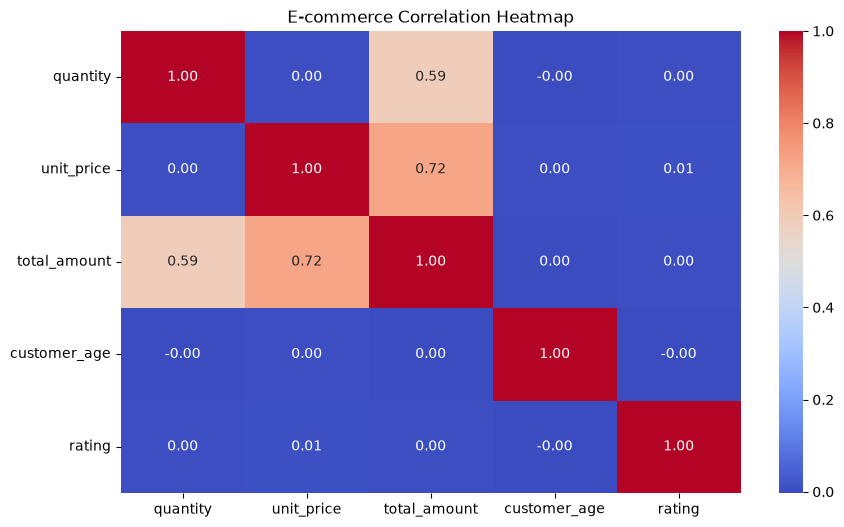

In [201]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('E-commerce Correlation Heatmap')

plt.show()

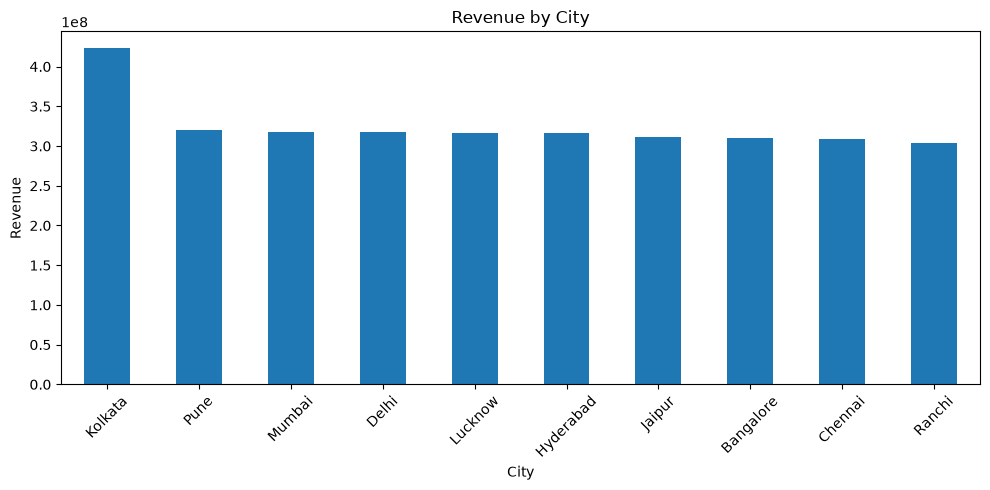

In [ ]:
city_revenue.plot(
    kind='bar',
    figsize=(10, 5),
    title='Revenue by City'
)

plt.xlabel('City')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

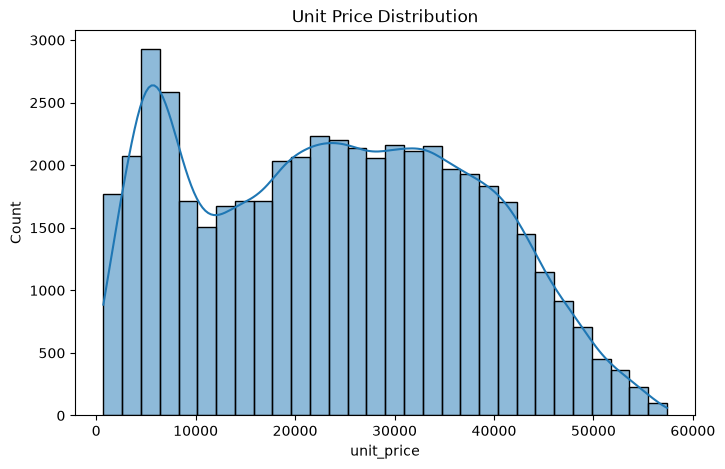

In [203]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='unit_price',
    bins=30,
    kde=True
)

plt.title('Unit Price Distribution')
plt.show()

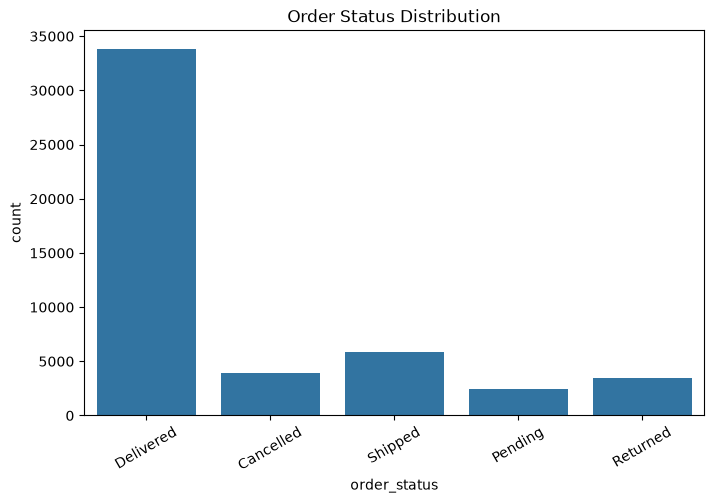

In [206]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='order_status'
)

plt.title('Order Status Distribution')
plt.xticks(rotation=30)
plt.show()

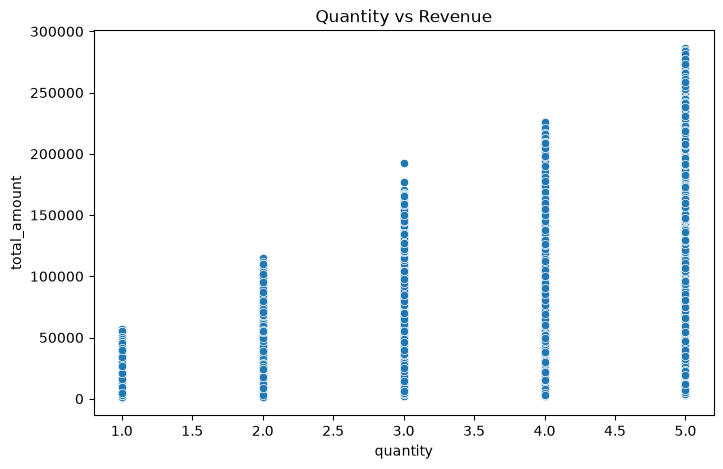

In [207]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='quantity',
    y='total_amount'
)

plt.title('Quantity vs Revenue')
plt.show()

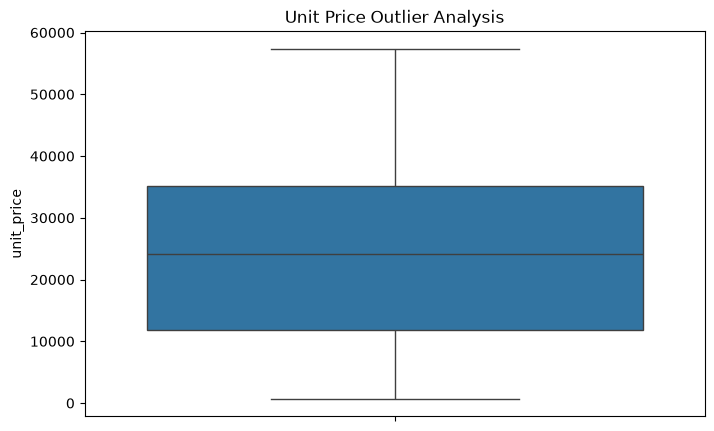

In [208]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    y='unit_price'
)

plt.title('Unit Price Outlier Analysis')
plt.show()

In [212]:
avg_qty_per_order=df['quantity'].mean()
avg_qty_per_order

np.float64(2.99343430274712)

In [214]:
top_10_customers_by_spending=df.groupby('customer_id')['total_amount'].sum().sort_values(ascending=False).head(10)
top_10_customers_by_spending

customer_id
CUST15762    2178412.36
CUST11251    1781891.91
CUST14663    1681732.01
CUST15067    1514754.03
CUST11021    1472681.78
CUST10190    1429308.54
CUST10282    1411754.00
CUST15020    1382976.88
CUST13670    1365423.95
CUST10609    1355715.95
Name: total_amount, dtype: float64

In [215]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_id', 'quantity',
       'unit_price', 'discount', 'total_amount', 'payment_method',
       'order_status', 'sales_channel', 'shipping_city', 'customer_age',
       'returned', 'rating', 'coupon_code', 'device', 'marketing_source'],
      dtype='str')

In [216]:
revenue_by_sales_channel=df.groupby('sales_channel')['total_amount'].sum()
revenue_by_sales_channel

sales_channel
In-store       8.044999e+08
Marketplace    8.141996e+08
Mobile App     8.153751e+08
Website        8.096882e+08
Name: total_amount, dtype: float64

In [217]:
avg_rating_by_order_status=df.groupby('order_status')['rating'].mean()
avg_rating_by_order_status

order_status
Cancelled    3.918207
Delivered    3.922154
Pending      3.927302
Returned     3.935031
Shipped      3.909276
Name: rating, dtype: float64

In [219]:
percentage_of_each_order_status=df['order_status'].value_counts(normalize=True)
percentage_of_each_order_status

order_status
Delivered    0.681463
Shipped      0.118767
Cancelled    0.079534
Returned     0.070370
Pending      0.049867
Name: proportion, dtype: float64

<Axes: title={'center': 'revenue by city'}, xlabel='shipping_city'>

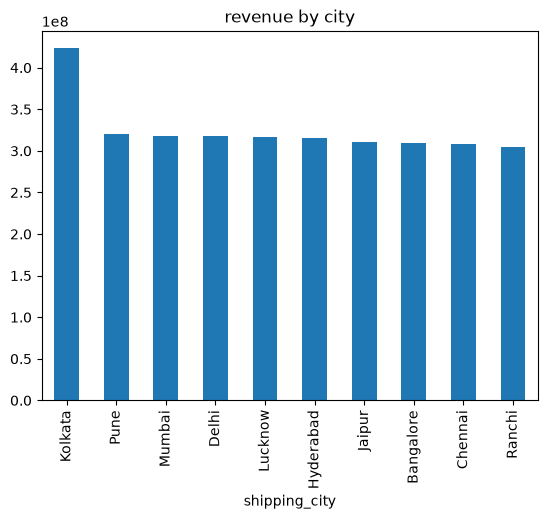

In [226]:
city_revenue.plot(kind='bar',title='revenue by city')

In [ ]:
from sqlalchemy import create_engine,text
from sqlalchemy.engine import URL

connection_url=URL.create(
    drivername='mysql+pymysql'
    username='root'
    password='Qwerty#@123'
    host='127.0.0.1'
    port=int(3306)
    database='second'
)

engine=create_engine(connection_url)

In [ ]:
query='select* from second'
df=pd.read_sql(query,con=engine)